In [10]:
from google.colab import drive
drive.mount('/content/drive')
!pip install torchinfo

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip install ultralytics
from ultralytics import YOLO

base_model = YOLO('yolov8m.pt')
fine_tuned_model = YOLO("/content/drive/MyDrive/CustomTrainedModels/yolov8m_finetuned_1024_run_py/weights/best.pt")

## Inspecting Architecture of The Base Model

In [6]:
print(base_model.model)

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(48, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(96, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(192, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
   

The head of the YOLOv8 model is defined in layer 22, called the Detect layer. It is responsible for generating the final predictions: bounding box coordinates, objectness scores, and class probabilities.

It operates at three different spatial scales to detect objects of different sizes. Each scale has two parallel branches:

The cv2 branch processes feature maps to help refine spatial information. While it does not produce the final outputs directly, it contributes to the internal feature representation used by the next branch.

The cv3 branch generates the actual predictions. Its final convolutional layers output the bounding box coordinates, the objectness score (confidence that an object is present), and the class probabilities.

Finally, the DFL (Distribution Focal Loss) layer is applied to improve the precision of the predicted bounding boxes by modeling coordinates as discrete probability distributions.

## Inspecting Architecture of Fine Tuned Model

In [7]:
print(fine_tuned_model.model)

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(48, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(96, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(192, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
   

In the fine-tuned model, the detection head (layer 22: Detect) remains structurally similar to the original base model architecture but is adapted for single-class (car) detection.

The cv3 branch, which produces the final predictions, is changed so that its last convolutional layer outputs 1 channel instead of 80, confirming the presence of only one object class.

## Number of parameters

In [14]:
total_params = sum(p.numel() for p in base_model.model.parameters())
print(f"Base Model Total parameters: {total_params}")

total_params = sum(p.numel() for p in fine_tuned_model.model.parameters())
print(f"Fine Tuned Total parameters: {total_params}")

Base Model Total parameters: 25902640
Fine Tuned Total parameters: 25856899


## List of layers with updated weights

In [12]:
import torch

for (name1, p1), (name2, p2) in zip(base_model.model.named_parameters(), fine_tuned_model.model.named_parameters()):
    if not torch.allclose(p1, p2):
        print(f"Weights differ in layer: {name1}")

Weights differ in layer: model.0.conv.weight
Weights differ in layer: model.0.bn.weight
Weights differ in layer: model.0.bn.bias
Weights differ in layer: model.1.conv.weight
Weights differ in layer: model.1.bn.weight
Weights differ in layer: model.1.bn.bias
Weights differ in layer: model.2.cv1.conv.weight
Weights differ in layer: model.2.cv1.bn.weight
Weights differ in layer: model.2.cv1.bn.bias
Weights differ in layer: model.2.cv2.conv.weight
Weights differ in layer: model.2.cv2.bn.weight
Weights differ in layer: model.2.cv2.bn.bias
Weights differ in layer: model.2.m.0.cv1.conv.weight
Weights differ in layer: model.2.m.0.cv1.bn.weight
Weights differ in layer: model.2.m.0.cv1.bn.bias
Weights differ in layer: model.2.m.0.cv2.conv.weight
Weights differ in layer: model.2.m.0.cv2.bn.weight
Weights differ in layer: model.2.m.0.cv2.bn.bias
Weights differ in layer: model.2.m.1.cv1.conv.weight
Weights differ in layer: model.2.m.1.cv1.bn.weight
Weights differ in layer: model.2.m.1.cv1.bn.bias
W

## Differences in Number of Classes

In [13]:
print("Base model classes:", base_model.model.model[-1].nc)
print("Fine-tuned model classes:", fine_tuned_model.model.model[-1].nc)

Base model classes: 80
Fine-tuned model classes: 1


## Visualization of weights distribution in different layers

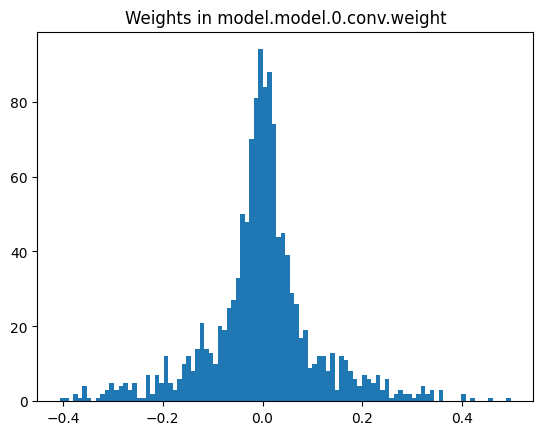

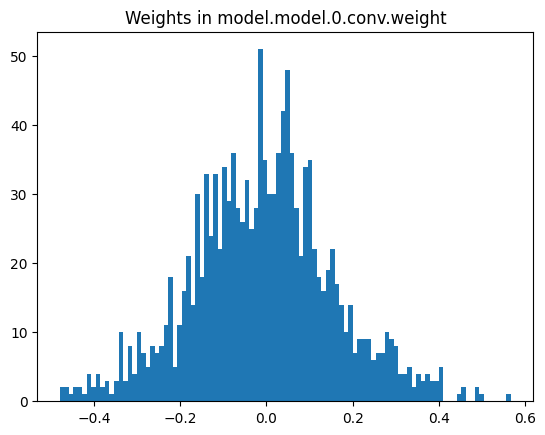

In [18]:
import matplotlib.pyplot as plt

def plot_weights(model, layer_name):
    param_dict = dict(model.named_parameters())
    if layer_name not in param_dict:
        print(f"Layer '{layer_name}' not found. Available keys:")
        for name in param_dict.keys():
            print(name)
        return
    weight = param_dict[layer_name].cpu().detach().numpy().flatten()
    plt.hist(weight, bins=100)
    plt.title(f"Weights in {layer_name}")
    plt.show()

plot_weights(base_model, 'model.model.0.conv.weight')
plot_weights(fine_tuned_model, 'model.model.0.conv.weight')

### Final classification layer

This comparison shows the weight distributions of the final classification layer (model.model.22.cv3.0.2.weight) in the base model (top) and fine-tuned model (bottom)

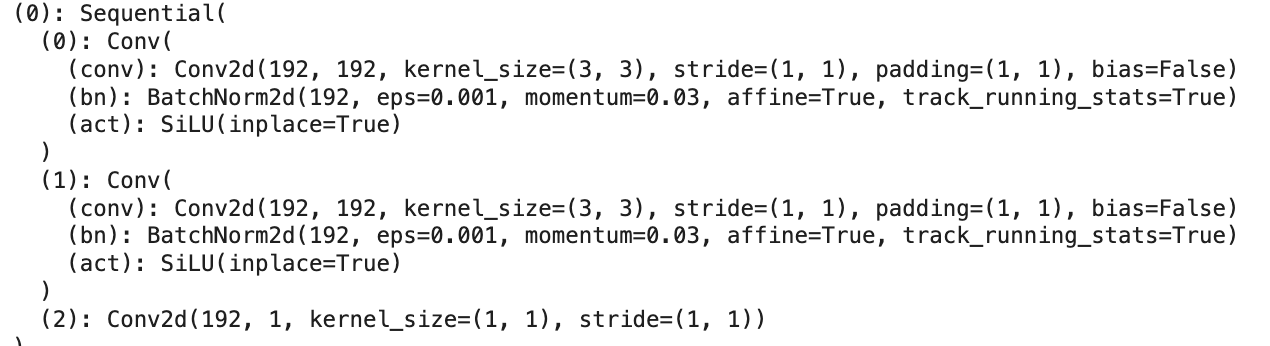

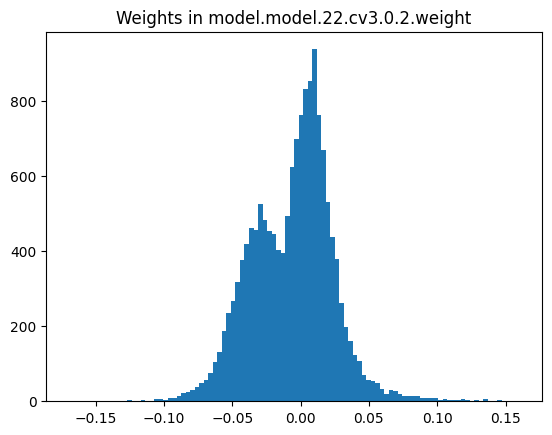

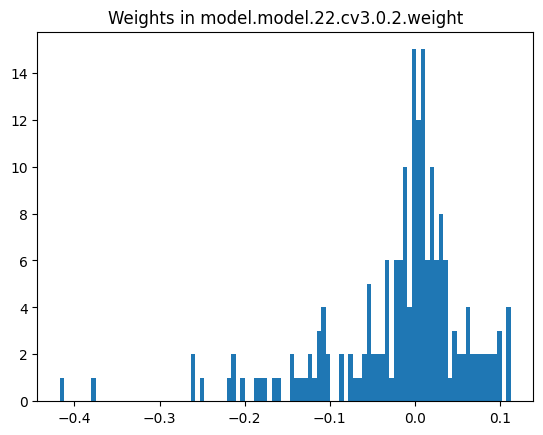

In [28]:
plot_weights(base_model, 'model.model.22.cv3.0.2.weight')
plot_weights(fine_tuned_model, 'model.model.22.cv3.0.2.weight')

The negative weight of -0.4 in the fine-tuned YOLOv8 model suggests that the model  learned to suppress some features that are not useful or misleading for the car detection task.

Also, the fine-tuned model shows a more irregular distribution, which indicates  the layer has been indeed updated during training to specialize for the new task.

## Number of layers

In [22]:
num_layers = sum(1 for _ in fine_tuned_model.modules())
print(f"Total modules (layers): {num_layers}")

Total modules (layers): 296


In [23]:
num_layers = sum(1 for _ in base_model.modules())
print(f"Total modules (layers): {num_layers}")

Total modules (layers): 296


In [24]:
import torch.nn as nn

conv_layers = [m for m in fine_tuned_model.modules() if isinstance(m, nn.Conv2d)]
print(f"Number of Conv2d layers: {len(conv_layers)}")

Number of Conv2d layers: 84
